# 05 — Test-set ViT image explainers

Uses only the saved final ViT and the frozen test images. No model training or fold-specific OOF explanations are performed. The notebook requires a working CUDA device and deliberately stops rather than falling back to CPU.

It produces Grad-CAM, class-agnostic attention rollout, Chefer-style gradient-weighted attention relevance, and blur-baseline occlusion maps for the frozen CWF predicted class and the ViT's own top class. Occlusion uses 16x16 patches at stride 16, aligned to the ViT-B/16 patch grid.

In [1]:
import hashlib
import math
import json
import platform
import time
from contextlib import contextmanager
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import PIL
import torch
import torch.nn.functional as F
import torchvision
from PIL import Image, ImageFilter
from torchvision import models

ROOT = Path(r"D:\\skin_project")
OUT_DIR = ROOT / "outputs"
CACHE_DIR = ROOT / "cache"
DEVICE = torch.device("cuda:0")
BATCH_SIZE = 8
OCCLUSION_BATCH_SIZE = 32
PATCH_SIZE = 16
PATCH_STRIDE = 16
BLUR_RADIUS = 32

if not torch.cuda.is_available():
    raise RuntimeError("A working CUDA GPU is required; CPU fallback is intentionally disabled.")
_ = torch.ones(1, device=DEVICE).add_(1)
torch.cuda.synchronize()

print("GPU:", torch.cuda.get_device_name(0))
print("Capability:", torch.cuda.get_device_capability(0))
print("CUDA runtime:", torch.version.cuda)
print("PyTorch:", torch.__version__, "torchvision:", torchvision.__version__)
print("Python:", platform.python_version(), "NumPy:", np.__version__)
print("GPU memory (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

GPU: NVIDIA GeForce RTX 5050 Laptop GPU
Capability: (12, 0)
CUDA runtime: 12.8
PyTorch: 2.7.1+cu128 torchvision: 0.22.1+cu128
Python: 3.11.15 NumPy: 2.4.6
GPU memory (GiB): 7.96


In [2]:
base = np.load(OUT_DIR / "base_outputs_v1.npz", allow_pickle=True)
fusion = np.load(OUT_DIR / "fusion_v1.npz", allow_pickle=True)
registry = json.loads((OUT_DIR / "MODEL_REGISTRY.json").read_text(encoding="utf-8"))
split = json.loads((OUT_DIR / "split_v1.json").read_text(encoding="utf-8"))
tree = np.load(OUT_DIR / "treeshap_v1.npz", allow_pickle=True)

CLASSES = [str(value) for value in base["classes"]]
N_CLASSES = len(CLASSES)
assert fusion["selected"].item() == "CWF"
assert np.array_equal(CLASSES, [str(value) for value in fusion["classes"]])

TEST_ROW_KEYS = np.asarray([str(value) for value in tree["test_row_keys"]])
assert np.array_equal(TEST_ROW_KEYS, np.asarray([str(value) for value in split["test_img_ids"]]))
assert len(TEST_ROW_KEYS) == 461
Y_TEST = base["y_test"].astype(np.int64)
XGB_TEST = base["test_xgb"].astype(np.float32)
VIT_SAVED_TEST = base["test_vit"].astype(np.float32)
CWF_SAVED_TEST = fusion["cwf_test"].astype(np.float32)
W_XGB = fusion["w_xgb"].astype(np.float32)

image_cache = torch.load(CACHE_DIR / "images_uint8_224.pt", map_location="cpu", weights_only=True)
TEST_IMAGES = image_cache["te"]
assert tuple(TEST_IMAGES.shape) == (len(TEST_ROW_KEYS), 3, 224, 224)
assert TEST_IMAGES.dtype == torch.uint8

checkpoint_path = OUT_DIR / "vit_final_v1.pt"
checkpoint_sha256 = hashlib.sha256(checkpoint_path.read_bytes()).hexdigest()
assert checkpoint_sha256 == registry["final"]["vit"]["sha256"]

model = models.vit_b_16(weights=None)
model.heads.head = torch.nn.Linear(model.heads.head.in_features, N_CLASSES)
state = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
model.load_state_dict(state, strict=True)
model.to(DEVICE).eval()

MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

def normalize_images(images_uint8):
    images = images_uint8.to(DEVICE, non_blocking=True).float().div_(255.0)
    return (images - MEAN) / STD

@torch.inference_mode()
def predict_vit(images_uint8, batch_size=32):
    outputs = []
    for start in range(0, len(images_uint8), batch_size):
        logits = model(normalize_images(images_uint8[start:start + batch_size]))
        outputs.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(outputs, axis=0)

VIT_TEST = predict_vit(TEST_IMAGES)
vit_probability_max_abs = float(np.max(np.abs(VIT_TEST - VIT_SAVED_TEST)))
vit_argmax_disagreements = int(np.sum(VIT_TEST.argmax(1) != VIT_SAVED_TEST.argmax(1)))
print("Final ViT checkpoint SHA256:", checkpoint_sha256)
print("Max probability delta vs frozen test output:", vit_probability_max_abs)
print("ViT argmax disagreements vs frozen output:", vit_argmax_disagreements)
assert vit_probability_max_abs <= 1e-3

TARGET_FUSED = CWF_SAVED_TEST.argmax(1).astype(np.int64)
TARGET_VIT = VIT_TEST.argmax(1).astype(np.int64)
CWF_REBUILT = W_XGB[None, :] * XGB_TEST + (1.0 - W_XGB[None, :]) * VIT_SAVED_TEST
CWF_REBUILT /= CWF_REBUILT.sum(axis=1, keepdims=True)
assert np.max(np.abs(CWF_REBUILT - CWF_SAVED_TEST)) < 1e-6
print("Frozen CWF target classes:", dict(zip(*np.unique(TARGET_FUSED, return_counts=True))))
print("Recomputed ViT-top target disagreements vs frozen ViT:", int(np.sum(TARGET_VIT != VIT_SAVED_TEST.argmax(1))))

Final ViT checkpoint SHA256: 601e57558f2968f46c2c43417f5c3139c09edf6abfa358eeba759caeced1639c
Max probability delta vs frozen test output: 0.0007751882076263428
ViT argmax disagreements vs frozen output: 1
Frozen CWF target classes: {np.int64(0): np.int64(136), np.int64(1): np.int64(183), np.int64(2): np.int64(10), np.int64(3): np.int64(55), np.int64(4): np.int64(26), np.int64(5): np.int64(51)}
Recomputed ViT-top target disagreements vs frozen ViT: 1


In [3]:
def normalize_maps(raw_maps):
    maps = torch.nan_to_num(raw_maps, nan=0.0, posinf=0.0, neginf=0.0).relu()
    flat = maps.flatten(1)
    low = flat.min(dim=1).values[:, None, None]
    high = flat.max(dim=1).values[:, None, None]
    return ((maps - low) / (high - low).clamp_min(1e-8)).clamp_(0, 1)

def gradcam_map(images, target_classes):
    activations = []
    handle = model.encoder.layers[-1].ln_1.register_forward_hook(
        lambda _module, _inputs, output: activations.append(output)
    )
    try:
        logits = model(images)
        score = logits.gather(1, target_classes[:, None]).sum()
        gradients = torch.autograd.grad(score, activations[0])[0]
    finally:
        handle.remove()
    patch_activations = activations[0][:, 1:, :]
    patch_gradients = gradients[:, 1:, :]
    channel_weights = patch_gradients.mean(dim=1, keepdim=True)
    raw = (patch_activations * channel_weights).sum(dim=-1).reshape(-1, 14, 14)
    return normalize_maps(raw)

@contextmanager
def capture_attentions():
    captured = []
    originals = []
    for block in model.encoder.layers:
        attention = block.self_attention
        original = attention.forward
        originals.append((attention, original))

        def wrapped(query, key, value, key_padding_mask=None, need_weights=True,
                    attn_mask=None, average_attn_weights=True, is_causal=False,
                    _attention=attention, _captured=captured):
            if query is not key or key is not value or key_padding_mask is not None or attn_mask is not None or is_causal:
                raise RuntimeError("Unexpected ViT self-attention arguments.")
            batch, sequence, embed = query.shape
            heads = _attention.num_heads
            head_dim = embed // heads
            q, k, v = F.linear(query, _attention.in_proj_weight, _attention.in_proj_bias).chunk(3, dim=-1)
            q = q.reshape(batch, sequence, heads, head_dim).transpose(1, 2) * (head_dim ** -0.5)
            k = k.reshape(batch, sequence, heads, head_dim).transpose(1, 2)
            v = v.reshape(batch, sequence, heads, head_dim).transpose(1, 2)
            weights = torch.softmax(q @ k.transpose(-2, -1), dim=-1)
            weights = F.dropout(weights, p=_attention.dropout, training=_attention.training)
            _captured.append(weights)
            output = (weights @ v).transpose(1, 2).reshape(batch, sequence, embed)
            output = F.linear(output, _attention.out_proj.weight, _attention.out_proj.bias)
            returned = weights.mean(dim=1) if average_attn_weights else weights
            return output, returned if need_weights else None

        attention.forward = wrapped
    try:
        yield captured
    finally:
        for attention, original in originals:
            attention.forward = original

def attention_rollout_map(images):
    with capture_attentions() as attentions:
        with torch.no_grad():
            _ = model(images)
    if len(attentions) != len(model.encoder.layers) or any(value is None for value in attentions):
        raise RuntimeError("Failed to capture attention weights from every ViT block.")
    tokens = attentions[0].shape[-1]
    identity = torch.eye(tokens, device=DEVICE).unsqueeze(0)
    joint = identity.expand(images.shape[0], -1, -1).clone()
    for attention in attentions:
        matrix = attention.mean(dim=1) + identity
        matrix = matrix / matrix.sum(dim=-1, keepdim=True).clamp_min(1e-8)
        joint = matrix @ joint
    return normalize_maps(joint[:, 0, 1:].reshape(-1, 14, 14))

def chefer_map(images, target_classes):
    with capture_attentions() as attentions:
        logits = model(images)
        score = logits.gather(1, target_classes[:, None]).sum()
        gradients = torch.autograd.grad(score, tuple(attentions))
    if len(attentions) != len(model.encoder.layers):
        raise RuntimeError("Failed to capture attention weights from every ViT block.")
    tokens = attentions[0].shape[-1]
    identity = torch.eye(tokens, device=DEVICE).unsqueeze(0)
    joint = identity.expand(images.shape[0], -1, -1).clone()
    for attention, gradient in zip(attentions, gradients):
        relevance = (attention * gradient).clamp_min(0).mean(dim=1) + identity
        relevance = relevance / relevance.sum(dim=-1, keepdim=True).clamp_min(1e-8)
        joint = relevance @ joint
    return normalize_maps(joint[:, 0, 1:].reshape(-1, 14, 14))

In [4]:
N_TEST = len(TEST_ROW_KEYS)
gradcam_fused = np.empty((N_TEST, 14, 14), dtype=np.float16)
gradcam_vit_top = np.empty_like(gradcam_fused)
chefer_fused = np.empty_like(gradcam_fused)
chefer_vit_top = np.empty_like(gradcam_fused)
attention_rollout = np.empty_like(gradcam_fused)

gradient_start = time.perf_counter()
for start in range(0, N_TEST, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N_TEST)
    images = normalize_images(TEST_IMAGES[start:end])
    fused_targets = torch.as_tensor(TARGET_FUSED[start:end], device=DEVICE)
    vit_targets = torch.as_tensor(TARGET_VIT[start:end], device=DEVICE)

    gradcam_fused[start:end] = gradcam_map(images, fused_targets).detach().cpu().numpy().astype(np.float16)
    gradcam_vit_top[start:end] = gradcam_map(images, vit_targets).detach().cpu().numpy().astype(np.float16)
    chefer_fused[start:end] = chefer_map(images, fused_targets).detach().cpu().numpy().astype(np.float16)
    chefer_vit_top[start:end] = chefer_map(images, vit_targets).detach().cpu().numpy().astype(np.float16)
    attention_rollout[start:end] = attention_rollout_map(images).detach().cpu().numpy().astype(np.float16)

    if end % 64 == 0 or end == N_TEST:
        print(f"Gradient/attention maps: {end}/{N_TEST}")

print("Gradient and attention stage seconds:", round(time.perf_counter() - gradient_start, 1))
torch.cuda.synchronize()

Gradient/attention maps: 64/461
Gradient/attention maps: 128/461
Gradient/attention maps: 192/461
Gradient/attention maps: 256/461
Gradient/attention maps: 320/461
Gradient/attention maps: 384/461
Gradient/attention maps: 448/461
Gradient/attention maps: 461/461
Gradient and attention stage seconds: 65.5


In [5]:
def normalize_numpy_map(raw_map):
    values = np.maximum(np.nan_to_num(raw_map, nan=0.0, posinf=0.0, neginf=0.0), 0.0)
    low, high = float(values.min()), float(values.max())
    if high - low <= 1e-8:
        return np.zeros_like(values, dtype=np.float16)
    return ((values - low) / (high - low)).astype(np.float16)

def blur_uint8(image_uint8):
    array = image_uint8.permute(1, 2, 0).contiguous().numpy()
    blurred = Image.fromarray(array).filter(ImageFilter.GaussianBlur(radius=BLUR_RADIUS))
    return torch.from_numpy(np.asarray(blurred, dtype=np.uint8).copy()).permute(2, 0, 1)

PATCHES = [(top, left) for top in range(0, 224 - PATCH_SIZE + 1, PATCH_STRIDE)
           for left in range(0, 224 - PATCH_SIZE + 1, PATCH_STRIDE)]
assert len(PATCHES) == 196
blurred_test = torch.stack([blur_uint8(image) for image in TEST_IMAGES])
occlusion_fused = np.empty((N_TEST, 14, 14), dtype=np.float16)
occlusion_vit_top = np.empty_like(occlusion_fused)

occlusion_start = time.perf_counter()
for row in range(N_TEST):
    variants = TEST_IMAGES[row].unsqueeze(0).repeat(len(PATCHES), 1, 1, 1)
    blurred = blurred_test[row]
    for patch_index, (top, left) in enumerate(PATCHES):
        variants[patch_index, :, top:top + PATCH_SIZE, left:left + PATCH_SIZE] = blurred[
            :, top:top + PATCH_SIZE, left:left + PATCH_SIZE
        ]

    fused_drops = []
    vit_drops = []
    fused_target = int(TARGET_FUSED[row])
    vit_target = int(TARGET_VIT[row])
    for start in range(0, len(PATCHES), OCCLUSION_BATCH_SIZE):
        batch = normalize_images(variants[start:start + OCCLUSION_BATCH_SIZE])
        with torch.inference_mode():
            probabilities = torch.softmax(model(batch), dim=1)
        fused_drops.append((VIT_TEST[row, fused_target] - probabilities[:, fused_target].cpu().numpy()))
        vit_drops.append((VIT_TEST[row, vit_target] - probabilities[:, vit_target].cpu().numpy()))

    occlusion_fused[row] = normalize_numpy_map(np.concatenate(fused_drops).reshape(14, 14))
    occlusion_vit_top[row] = normalize_numpy_map(np.concatenate(vit_drops).reshape(14, 14))
    if (row + 1) % 25 == 0 or row + 1 == N_TEST:
        print(f"Occlusion maps: {row + 1}/{N_TEST}")

torch.cuda.synchronize()
print("Occlusion stage seconds:", round(time.perf_counter() - occlusion_start, 1))

Occlusion maps: 25/461
Occlusion maps: 50/461
Occlusion maps: 75/461
Occlusion maps: 100/461
Occlusion maps: 125/461
Occlusion maps: 150/461
Occlusion maps: 175/461
Occlusion maps: 200/461
Occlusion maps: 225/461
Occlusion maps: 250/461
Occlusion maps: 275/461
Occlusion maps: 300/461
Occlusion maps: 325/461
Occlusion maps: 350/461
Occlusion maps: 375/461
Occlusion maps: 400/461
Occlusion maps: 425/461
Occlusion maps: 450/461
Occlusion maps: 461/461
Occlusion stage seconds: 1708.7


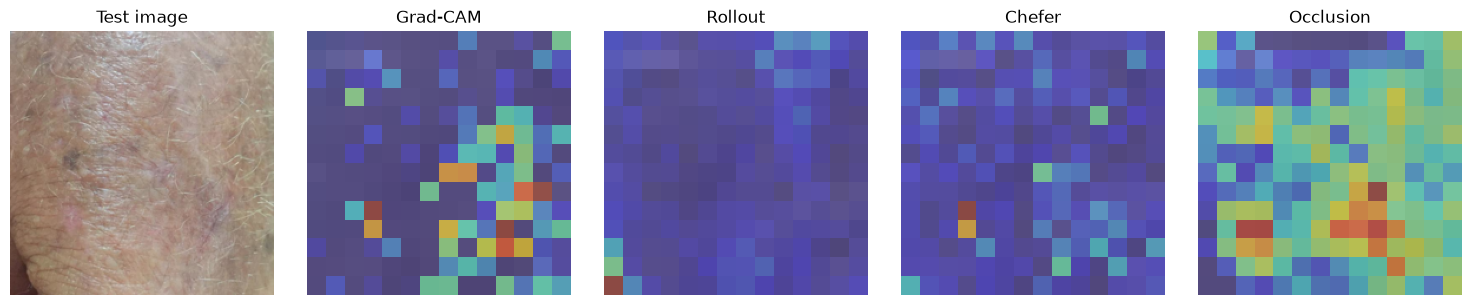

Saved: D:\skin_project\outputs\image_explainers_v1.npz
Verified maps: {'gradcam_fused': (461, 14, 14), 'gradcam_vit_top': (461, 14, 14), 'attention_rollout_fused': (461, 14, 14), 'attention_rollout_vit_top': (461, 14, 14), 'chefer_fused': (461, 14, 14), 'chefer_vit_top': (461, 14, 14), 'occlusion_fused': (461, 14, 14), 'occlusion_vit_top': (461, 14, 14)}


In [6]:
MAPS = {
    "gradcam_fused": gradcam_fused,
    "gradcam_vit_top": gradcam_vit_top,
    "attention_rollout_fused": attention_rollout,
    "attention_rollout_vit_top": attention_rollout,
    "chefer_fused": chefer_fused,
    "chefer_vit_top": chefer_vit_top,
    "occlusion_fused": occlusion_fused,
    "occlusion_vit_top": occlusion_vit_top,
}
for name, maps in MAPS.items():
    assert maps.shape == (N_TEST, 14, 14), (name, maps.shape)
    assert maps.dtype == np.float16, (name, maps.dtype)
    assert np.isfinite(maps).all(), name
    assert float(maps.min()) >= 0.0 and float(maps.max()) <= 1.0, name

config = {
    "scope": "frozen test set only; final saved ViT; no training; no OOF image maps",
    "primary_target": "frozen CWF test predicted class; ViT attribution uses that class logit/probability",
    "secondary_target": "recomputed final ViT top class",
    "normalization": "ReLU then per-map min-max; constant maps become zeros",
    "gradcam_layer": "model.encoder.layers[-1].ln_1; class-logit gradients",
    "attention_rollout": "head-mean attention with identity residual; class-independent",
    "chefer": "positive attention-times-class-logit-gradient, head mean, residual rollout",
    "occlusion": "replace each raw 16x16 patch with the corresponding Gaussian-blurred pixels; report target-probability drop",
    "patch_size": PATCH_SIZE,
    "patch_stride": PATCH_STRIDE,
    "blur_radius": BLUR_RADIUS,
    "gradient_batch_size": BATCH_SIZE,
    "occlusion_batch_size": OCCLUSION_BATCH_SIZE,
    "device": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "cuda_runtime": torch.version.cuda,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pillow": PIL.__version__,
}

sample = 0
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(TEST_IMAGES[sample].permute(1, 2, 0).numpy())
axes[0].set_title("Test image")
for axis, (name, maps) in zip(axes[1:], [("Grad-CAM", gradcam_fused), ("Rollout", attention_rollout), ("Chefer", chefer_fused), ("Occlusion", occlusion_fused)]):
    axis.imshow(TEST_IMAGES[sample].permute(1, 2, 0).numpy())
    axis.imshow(maps[sample], cmap="jet", alpha=0.45, vmin=0, vmax=1)
    axis.set_title(name)
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

artifact_path = OUT_DIR / "image_explainers_v1.npz"
np.savez_compressed(
    artifact_path,
    classes=np.asarray(CLASSES),
    test_row_keys=TEST_ROW_KEYS,
    test_true_y=Y_TEST,
    target_fused_class=TARGET_FUSED,
    target_vit_top_class=TARGET_VIT,
    vit_probability_max_abs=np.asarray(vit_probability_max_abs),
    vit_argmax_disagreements=np.asarray(vit_argmax_disagreements),
    gradcam_fused=gradcam_fused,
    gradcam_vit_top=gradcam_vit_top,
    attention_rollout_fused=attention_rollout,
    attention_rollout_vit_top=attention_rollout,
    chefer_fused=chefer_fused,
    chefer_vit_top=chefer_vit_top,
    occlusion_fused=occlusion_fused,
    occlusion_vit_top=occlusion_vit_top,
    config_json=np.asarray(json.dumps(config, sort_keys=True)),
)
print("Saved:", artifact_path)
print("Verified maps:", {name: maps.shape for name, maps in MAPS.items()})